# LIrAs User Study — exploratory analysis notebook

This notebook reads the **scoring workbook as the single source of truth** and supports exploratory analysis of the 20 study responses.

It is designed to answer three practical questions before writing the paper:

1. **How well did participants perform on the study tasks?**
2. **Do the Known and Prolific cohorts behave differently enough that the distinction matters?**
3. **How do prior background and subjective perceptions relate to task performance?**

### Statistical stance

- Sample sizes are small (`n=10` per cohort), and several task scores have clear ceiling effects.
- Cohort comparisons therefore use **Mann–Whitney U** tests plus a rank-based effect size rather than relying only on means or parametric tests.
- Associations between ordered background/feedback variables and performance use **Spearman correlations**.
- Benjamini–Hochberg adjusted p-values (`q`) are provided for families of exploratory tests.
- Treat p-values as exploratory evidence, not as the only criterion for deciding what is scientifically relevant.

## 1. Setup and input file

Place this notebook in the same directory as the scoring workbook. The code first looks for `LIrAs_User_Study_Scoring.xlsx`, then for any `LIrAs_User_Study_Scoring.xlsx` file in the current directory.

Optional dependency: `ipywidgets`. If available, interactive dropdown selectors are enabled. If it is not installed, all analyses still work and the notebook provides ordinary function calls instead.

In [1]:
from pathlib import Path
from collections import OrderedDict
import math
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr, kruskal, fisher_exact
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 180)

# Optional widgets
try:
    import ipywidgets as widgets
    WIDGETS_AVAILABLE = True
except Exception:
    WIDGETS_AVAILABLE = False


def locate_scoring_file():
    preferred_names = [
        'LIrAs_User_Study_Scoring.xlsx',
    ]
    search_dirs = [Path.cwd()]
    for d in search_dirs:
        for name in preferred_names:
            p = d / name
            if p.exists():
                return p.resolve()
    candidates = []
    for d in search_dirs:
        if d.exists():
            candidates.extend(d.glob('LIrAs_User_Study_Scoring*.xlsx'))
    if not candidates:
        raise FileNotFoundError('Could not find LIrAs_User_Study_Scoring*.xlsx')
    return max(candidates, key=lambda p: p.stat().st_mtime).resolve()

SCORING_FILE = locate_scoring_file()
OUTPUT_DIR = SCORING_FILE.parent / 'liras_analysis_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

print('Input:', SCORING_FILE)
print('Outputs:', OUTPUT_DIR)
print('Interactive widgets:', 'available' if WIDGETS_AVAILABLE else 'not installed (static fallback will be used)')

Input: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/LIrAs_User_Study_Scoring.xlsx
Outputs: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/liras_analysis_outputs
Interactive widgets: available


## 2. Load and harmonize the workbook

The manual-scoring sheets contain rubric rows before the participant table. The helper below finds the row containing `Blind ID` automatically, so the notebook is not tied to a fixed Excel row number.

In [2]:
def read_table_from_marker(file_path, sheet_name, marker='Blind ID'):
    raw = pd.read_excel(file_path, sheet_name=sheet_name, header=None, keep_default_na=False)
    marker_rows = []
    for i, row in raw.iterrows():
        if row.astype(str).str.strip().eq(marker).any():
            marker_rows.append(i)
    if not marker_rows:
        raise ValueError(f'Could not find header marker {marker!r} in sheet {sheet_name!r}')
    header_row = marker_rows[-1]
    df = pd.read_excel(file_path, sheet_name=sheet_name, header=header_row, keep_default_na=False)
    df = df.replace(r'^\s*$', np.nan, regex=True)
    df = df.dropna(how='all')
    if marker not in df.columns:
        raise ValueError(f'{marker!r} not found among parsed columns in {sheet_name!r}')
    return df

bg = read_table_from_marker(SCORING_FILE, 'Background & Feedback')
auto = read_table_from_marker(SCORING_FILE, 'Auto Scores')
t2 = read_table_from_marker(SCORING_FILE, 'T2 Scoring')
t3b = read_table_from_marker(SCORING_FILE, 'T3B Scoring')
t41 = read_table_from_marker(SCORING_FILE, 'T4.1 Scoring')
t42 = read_table_from_marker(SCORING_FILE, 'T4.2 Scoring')
participant_map = read_table_from_marker(SCORING_FILE, 'Participant Map')

# Keep only the columns needed downstream and give manual totals explicit names.
t2_small = t2[['Blind ID', 'Response', 'Total', 'Notes']].rename(
    columns={'Response':'T2 response', 'Total':'T2 total', 'Notes':'T2 notes'})
t3b_small = t3b[['Blind ID', 'Response', 'Total', 'Notes']].rename(
    columns={'Response':'T3B response', 'Total':'T3B total', 'Notes':'T3B notes'})
t41_small = t41[['Blind ID', 'Response', 'Total', 'Notes']].rename(
    columns={'Response':'T4.1 response', 'Total':'T4.1 total', 'Notes':'T4.1 notes'})
t42_small = t42[['Blind ID', 'Response', 'Total', 'Notes']].rename(
    columns={'Response':'T4.2 response', 'Total':'T4.2 total', 'Notes':'T4.2 notes'})

# Automatic scores: keep item-level correctness and totals, not the long response strings.
auto_small = auto[[
    'Blind ID', 'T1.1', 'T1.2', 'T1.3', 'T1.4', 'T1 total',
    'Err 1', 'Err 2', 'Err 3', 'T3A total'
]].copy()

analysis_df = bg.merge(auto_small, on='Blind ID', how='left', validate='one_to_one')
for part in [t2_small, t3b_small, t41_small, t42_small]:
    analysis_df = analysis_df.merge(part, on='Blind ID', how='left', validate='one_to_one')

# Numeric conversion for all scoring columns.
score_cols = ['T1.1','T1.2','T1.3','T1.4','T1 total','Err 1','Err 2','Err 3','T3A total',
              'T2 total','T3B total','T4.1 total','T4.2 total']
for c in score_cols:
    analysis_df[c] = pd.to_numeric(analysis_df[c], errors='coerce')

# Derived task-family totals.
analysis_df['T3 total'] = analysis_df['T3A total'] + analysis_df['T3B total']
analysis_df['Writing total'] = analysis_df['T4.1 total'] + analysis_df['T4.2 total']
analysis_df['Overall raw'] = (
    analysis_df['T1 total'] + analysis_df['T2 total'] + analysis_df['T3A total'] +
    analysis_df['T3B total'] + analysis_df['T4.1 total'] + analysis_df['T4.2 total']
)

TASK_MAX = OrderedDict([
    ('T1 total', 4.0),
    ('T2 total', 2.5),
    ('T3A total', 3.0),
    ('T3B total', 2.0),
    ('T3 total', 5.0),
    ('T4.1 total', 3.0),
    ('T4.2 total', 2.5),
    ('Writing total', 5.5),
    ('Overall raw', 17.0),
])

for c, max_score in TASK_MAX.items():
    analysis_df[c + ' pct'] = 100 * analysis_df[c] / max_score

# Mark known non-attempts/misplaced answers in T4.2 separately from their score of 0.
def infer_t42_attempted(row):
    response = str(row.get('T4.2 response', '') or '').strip().lower()
    note = str(row.get('T4.2 notes', '') or '').strip().lower()
    if not response:
        return False
    if 'ran out of time' in response:
        return False
    if 'previous' in note or 'preavious' in note or 'not answer' in note:
        return False
    return True

analysis_df['T4.2 attempted'] = analysis_df.apply(infer_t42_attempted, axis=1)

print(f'Participants loaded: {len(analysis_df)}')
display(analysis_df[['Blind ID','Cohort','T1 total','T2 total','T3A total','T3B total','T4.1 total','T4.2 total','Overall raw']].head())

Participants loaded: 20


/var/folders/hj/l73jjb214gv9mr818lpmn_8m0000gn/T/ipykernel_6426/4135066591.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(r'^\s*$', np.nan, regex=True)
/var/folders/hj/l73jjb214gv9mr818lpmn_8m0000gn/T/ipykernel_6426/4135066591.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(r'^\s*$', np.nan, regex=True)
/var/folders/hj/l73jjb214gv9mr818lpmn_8m0000gn/T/ipykernel_6426/4135066591.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To

,Blind ID,Cohort,T1 total,T2 total,T3A total,T3B total,T4.1 total,T4.2 total,Overall raw
0,S001,Known,4,2.5,3,2.0,3.0,2.5,17.0
1,S002,Known,4,1.5,3,2.0,3.0,2.5,16.0
2,S003,Prolific,2,0.5,2,2.0,1.0,0.0,7.5
3,S004,Known,4,2.0,2,1.5,3.0,2.5,15.0
4,S005,Known,4,0.5,2,1.0,2.5,2.5,12.5


## 3. Data-quality checks

Run this section before interpreting any result. It checks missing scores, score ranges, ID consistency, and the manually entered Notes fields.

In [3]:
def quality_checks(df):
    issues = []
    if not df['Blind ID'].is_unique:
        issues.append('Blind IDs are not unique.')

    expected_ids = set(participant_map['Blind ID'].dropna())
    observed_ids = set(df['Blind ID'].dropna())
    if expected_ids != observed_ids:
        issues.append(f'ID mismatch. Missing={expected_ids-observed_ids}; unexpected={observed_ids-expected_ids}')

    for col, max_score in TASK_MAX.items():
        bad = df.loc[(df[col] < 0) | (df[col] > max_score), ['Blind ID', col]]
        if not bad.empty:
            issues.append(f'Out-of-range values in {col}: {bad.to_dict("records")}')

    primary_scores = ['T1 total','T2 total','T3A total','T3B total','T4.1 total','T4.2 total']
    missing = df[primary_scores].isna().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        issues.append('Missing primary scores: ' + missing.to_dict().__repr__())

    if issues:
        print('CHECKS FOUND POSSIBLE ISSUES:')
        for item in issues:
            print(' -', item)
    else:
        print('All core structural checks passed.')

    print('\nCohort counts:')
    display(df['Cohort'].value_counts().rename('n').to_frame())

    print('\nT4.2 attempt status:')
    display(pd.crosstab(df['Cohort'], df['T4.2 attempted'], margins=True))

    notes_cols = ['T2 notes','T3B notes','T4.1 notes','T4.2 notes']
    notes = df[['Blind ID','Cohort'] + notes_cols].copy()
    notes = notes.loc[notes[notes_cols].notna().any(axis=1)]
    print('\nRows with scoring notes:')
    display(notes if len(notes) else pd.DataFrame({'message':['No scoring notes found.']}))

quality_checks(analysis_df)

All core structural checks passed.

Cohort counts:


,n
Cohort,
Known,10
Prolific,10



T4.2 attempt status:


T4.2 attempted,False,True,All
Cohort,,,
Known,0,10,10
Prolific,2,8,10
All,2,18,20



Rows with scoring notes:


,Blind ID,Cohort,T2 notes,T3B notes,T4.1 notes,T4.2 notes
2,S003,Prolific,NaN,NaN,NaN,Not Answer
7,S008,Prolific,NaN,NaN,NaN,This is the answer to the preavious question
11,S012,Prolific,NaN,NaN,NaN,Missing the Operator sequence


## 4. Ordered encodings for background and feedback

These numerical encodings are used **only** for ordered-variable analyses such as Spearman correlations. The original text columns remain unchanged.

In [4]:
experience_map = {'None':0, 'Basic':1, 'Limited':2, 'Moderate':3, 'Extensive':4}
programming_map = {'No programming experience':0, 'Less than 1 year':1, '1–3 years':2, 'More than 3':3}
familiarity_map = {
    'I had never heard of LIrAs.':0,
    'I had heard of LIrAs but had not read documentation or used it.':1,
    'I had read or seen material about LIrAs but had not used it.':2,
    'I had previously used LIrAs.':3,
    'I am not sure.':np.nan,
}
english_map = {
    'Beginner: Can understand and use basic, familiar phrases':0,
    'Intermediate: Can understand the main points of standard input on familiar matters':1,
    'Advanced: Can use language flexibly and effectively for complex purposes':2,
    'Proficient: Can understand virtually everything heard or read with ease':3,
    'Native speaker':4,
}
likert_map = {
    'Strongly disagree':1,
    'Disagree':2,
    'Neither agree nor disagree':3,
    'Agree':4,
    'Strongly agree':5,
}

def mental_effort_to_num(value):
    if pd.isna(value):
        return np.nan
    first = str(value).split('—')[0].strip().lower()
    mapping = {'very low':1, 'low':2, 'moderate':3, 'high':4, 'very high':5}
    return mapping.get(first, np.nan)

analysis_df['Programming experience ord'] = analysis_df['Programming experience'].map(programming_map)
analysis_df['LIrAs familiarity ord'] = analysis_df['LIrAs familiarity'].map(familiarity_map)
analysis_df['English reading ord'] = analysis_df['English technical reading'].map(english_map)
analysis_df['Mental effort ord'] = analysis_df['Mental effort'].apply(mental_effort_to_num)

exp_cols = ['Exp: Textual DSLs','Exp: Modeling notations','Exp: Uppaal/automata','Exp: Formal methods','Exp: Robotics/MAS/HRI']
for c in exp_cols:
    analysis_df[c + ' ord'] = analysis_df[c].map(experience_map)

analysis_df['Prior technical experience index'] = analysis_df[[c+' ord' for c in exp_cols]].mean(axis=1)
analysis_df['Formal/modeling experience index'] = analysis_df[[
    'Exp: Textual DSLs ord','Exp: Modeling notations ord','Exp: Uppaal/automata ord','Exp: Formal methods ord'
]].mean(axis=1)

LIRAS_FEEDBACK = [
    'LIrAs: Syntax', 'LIrAs: Scenario -> specification', 'LIrAs: Synchronization',
    'LIrAs: Continuations', 'LIrAs: Conditional constructs', 'LIrAs: Skip/restart', 'LIrAs: Confidence'
]
TUTORIAL_FEEDBACK = [
    'Tutorial: Clarity', 'Tutorial: Actions/predicates/parameters', 'Tutorial: Examples', 'Tutorial: Sufficient information'
]
for c in LIRAS_FEEDBACK + TUTORIAL_FEEDBACK:
    analysis_df[c + ' ord'] = analysis_df[c].map(likert_map)

BACKGROUND_ORDINAL = OrderedDict([
    ('Programming experience', 'Programming experience ord'),
    ('Textual DSL experience', 'Exp: Textual DSLs ord'),
    ('Modeling-notation experience', 'Exp: Modeling notations ord'),
    ('Uppaal/automata experience', 'Exp: Uppaal/automata ord'),
    ('Formal-methods experience', 'Exp: Formal methods ord'),
    ('Robotics/MAS/HRI experience', 'Exp: Robotics/MAS/HRI ord'),
    ('Prior LIrAs familiarity', 'LIrAs familiarity ord'),
    ('English technical reading', 'English reading ord'),
    ('Prior technical experience index', 'Prior technical experience index'),
    ('Formal/modeling experience index', 'Formal/modeling experience index'),
])

print('Ordinal mappings prepared.')

Ordinal mappings prepared.


## 5. Sample/background overview

This section is useful both for describing the participant sample and for judging whether the two cohorts are compositionally very different before deciding whether to pool them in the paper.

In [5]:
def show_background_overview(df=analysis_df):
    print('Role by cohort')
    display(pd.crosstab(df['Role'], df['Cohort'], margins=True))
    print('\nBackground area by cohort')
    display(pd.crosstab(df['Background area'], df['Cohort'], margins=True))
    print('\nProgramming experience by cohort')
    display(pd.crosstab(df['Programming experience'], df['Cohort'], margins=True))
    print('\nPrior LIrAs familiarity by cohort')
    display(pd.crosstab(df['LIrAs familiarity'], df['Cohort'], margins=True))

show_background_overview()

Role by cohort


Cohort,Known,Prolific,All
Role,,,
Academic researcher,3,0,3
Bachelor’s or Master’s student,0,3,3
Industry practitioner,2,5,7
Other role,2,2,4
PhD student,3,0,3
All,10,10,20



Background area by cohort


Cohort,Known,Prolific,All
Background area,,,
Computer Science or Software Engineering,7,6,13
Other field,0,1,1
Other technical/scientific field,2,2,4
"Robotics, Automation, Control, or Human–Robot Interaction",1,1,2
All,10,10,20



Programming experience by cohort


Cohort,Known,Prolific,All
Programming experience,,,
1–3 years,2,0,2
Less than 1 year,0,3,3
More than 3,8,6,14
No programming experience,0,1,1
All,10,10,20



Prior LIrAs familiarity by cohort


Cohort,Known,Prolific,All
LIrAs familiarity,,,
I had heard of LIrAs but had not read documentation or used it.,3,4,7
I had never heard of LIrAs.,6,6,12
I had read or seen material about LIrAs but had not used it.,1,0,1
All,10,10,20


In [6]:
def bh_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full(len(p), np.nan)
    mask = np.isfinite(p)
    if mask.sum() == 0:
        return q
    vals = p[mask]
    order = np.argsort(vals)
    ranked = vals[order]
    m = len(ranked)
    adj = ranked * m / np.arange(1, m+1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0, 1)
    back = np.empty(m)
    back[order] = adj
    q[mask] = back
    return q


def rank_biserial_from_u(u, n1, n2):
    # Positive values mean the first group tends to have larger observations.
    return 2 * u / (n1 * n2) - 1


def compare_two_cohorts(df, variables, labels=None):
    labels = labels or {v:v for v in variables}
    rows = []
    for var in variables:
        a = pd.to_numeric(df.loc[df['Cohort']=='Known', var], errors='coerce').dropna().values
        b = pd.to_numeric(df.loc[df['Cohort']=='Prolific', var], errors='coerce').dropna().values
        if len(a) == 0 or len(b) == 0:
            continue
        u, p = mannwhitneyu(a, b, alternative='two-sided', method='auto')
        rows.append({
            'Variable': labels.get(var, var),
            'Known n':len(a), 'Known median':np.median(a), 'Known mean':np.mean(a),
            'Prolific n':len(b), 'Prolific median':np.median(b), 'Prolific mean':np.mean(b),
            'Median difference (Known-Prolific)':np.median(a)-np.median(b),
            'Rank-biserial effect':rank_biserial_from_u(u, len(a), len(b)),
            'p':p,
        })
    out = pd.DataFrame(rows)
    if len(out):
        out['q (BH)'] = bh_adjust(out['p'])
        out = out.sort_values(['q (BH)','p'])
    return out

background_comp = compare_two_cohorts(
    analysis_df,
    list(BACKGROUND_ORDINAL.values()),
    labels={v:k for k,v in BACKGROUND_ORDINAL.items()}
)
print('Exploratory comparison of ordered background variables between cohorts:')
display(background_comp.round(3))

Exploratory comparison of ordered background variables between cohorts:


,Variable,Known n,Known median,Known mean,Prolific n,Prolific median,Prolific mean,Median difference (Known-Prolific),Rank-biserial effect,p,q (BH)
2,Modeling-notation experience,10,3.00,2.400,10,2.00,1.800,1.0,0.34,0.198,0.904
0,Programming experience,10,3.00,2.800,10,3.00,2.100,0.0,0.28,0.207,0.904
7,English technical reading,10,3.00,2.600,10,3.00,3.000,0.0,-0.20,0.416,0.904
9,Formal/modeling experience index,10,1.75,1.625,10,1.25,1.325,0.5,0.18,0.519,0.904
8,Prior technical experience index,10,1.50,1.600,10,1.10,1.320,0.4,0.17,0.544,0.904
4,Formal-methods experience,10,1.00,1.400,10,1.00,1.100,0.0,0.09,0.751,0.904
5,Robotics/MAS/HRI experience,10,1.50,1.500,10,1.00,1.300,0.5,0.09,0.754,0.904
1,Textual DSL experience,10,1.50,1.500,10,1.00,1.300,0.5,0.06,0.843,0.904
6,Prior LIrAs familiarity,10,0.00,0.500,10,0.00,0.400,0.0,0.04,0.895,0.904
3,Uppaal/automata experience,10,1.00,1.200,10,0.50,1.100,0.5,0.04,0.904,0.904


## 6. Task-performance descriptives

The main performance table reports raw scores, percentage of the maximum, and ceiling rate. For T4.2, both the primary all-participant view and an attempted-only sensitivity view are available.

In [7]:
PRIMARY_TASKS = OrderedDict([
    ('Task 1 — understanding', ('T1 total', 4.0)),
    ('Task 2 — explanation', ('T2 total', 2.5)),
    ('Task 3A — identify debugging errors', ('T3A total', 3.0)),
    ('Task 3B — correct debugging errors', ('T3B total', 2.0)),
    ('Task 4.1 — write basic pattern', ('T4.1 total', 3.0)),
    ('Task 4.2 — write intermediate pattern', ('T4.2 total', 2.5)),
])


def select_cohort(df, cohort='All'):
    if cohort == 'All':
        return df.copy()
    return df.loc[df['Cohort'].eq(cohort)].copy()


def task_descriptives(df, cohort='All', t42_attempted_only=False):
    d = select_cohort(df, cohort)
    rows = []
    for label, (col, max_score) in PRIMARY_TASKS.items():
        dd = d
        if col == 'T4.2 total' and t42_attempted_only:
            dd = dd.loc[dd['T4.2 attempted']]
        x = pd.to_numeric(dd[col], errors='coerce').dropna()
        rows.append({
            'Task':label,
            'n':len(x),
            'Mean':x.mean(),
            'SD':x.std(ddof=1),
            'Median':x.median(),
            'Q1':x.quantile(.25),
            'Q3':x.quantile(.75),
            'Min':x.min(),
            'Max observed':x.max(),
            'Max possible':max_score,
            'Mean % of max':100*x.mean()/max_score,
            'Median % of max':100*x.median()/max_score,
            'At ceiling %':100*(x.eq(max_score)).mean(),
        })
    return pd.DataFrame(rows)

print('All participants, scores as entered in the workbook:')
display(task_descriptives(analysis_df).round(2))

print('\nSensitivity view: T4.2 among participants who actually attempted that task:')
display(task_descriptives(analysis_df, t42_attempted_only=True).round(2))

All participants, scores as entered in the workbook:


,Task,n,Mean,SD,Median,Q1,Q3,Min,Max observed,Max possible,Mean % of max,Median % of max,At ceiling %
0,Task 1 — understanding,20,3.80,0.52,4.0,4.00,4.0,2.0,4.0,4.0,95.00,100.0,85.0
1,Task 2 — explanation,20,2.05,0.67,2.5,2.00,2.5,0.5,2.5,2.5,82.00,100.0,55.0
2,Task 3A — identify debugging errors,20,2.80,0.41,3.0,3.00,3.0,2.0,3.0,3.0,93.33,100.0,80.0
3,Task 3B — correct debugging errors,20,1.80,0.38,2.0,1.88,2.0,1.0,2.0,2.0,90.00,100.0,75.0
4,Task 4.1 — write basic pattern,20,2.55,0.81,3.0,2.38,3.0,0.5,3.0,3.0,85.00,100.0,70.0
5,Task 4.2 — write intermediate pattern,20,2.10,0.82,2.5,2.38,2.5,0.0,2.5,2.5,84.00,100.0,75.0



Sensitivity view: T4.2 among participants who actually attempted that task:


,Task,n,Mean,SD,Median,Q1,Q3,Min,Max observed,Max possible,Mean % of max,Median % of max,At ceiling %
0,Task 1 — understanding,20,3.80,0.52,4.0,4.00,4.0,2.0,4.0,4.0,95.00,100.0,85.00
1,Task 2 — explanation,20,2.05,0.67,2.5,2.00,2.5,0.5,2.5,2.5,82.00,100.0,55.00
2,Task 3A — identify debugging errors,20,2.80,0.41,3.0,3.00,3.0,2.0,3.0,3.0,93.33,100.0,80.00
3,Task 3B — correct debugging errors,20,1.80,0.38,2.0,1.88,2.0,1.0,2.0,2.0,90.00,100.0,75.00
4,Task 4.1 — write basic pattern,20,2.55,0.81,3.0,2.38,3.0,0.5,3.0,3.0,85.00,100.0,70.00
5,Task 4.2 — write intermediate pattern,18,2.33,0.42,2.5,2.50,2.5,1.0,2.5,2.5,93.33,100.0,83.33


### Performance plot

Boxplots are combined with every individual observation, which is preferable to a violin density for this sample size.

/var/folders/hj/l73jjb214gv9mr818lpmn_8m0000gn/T/ipykernel_6426/696896246.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showmeans=True)


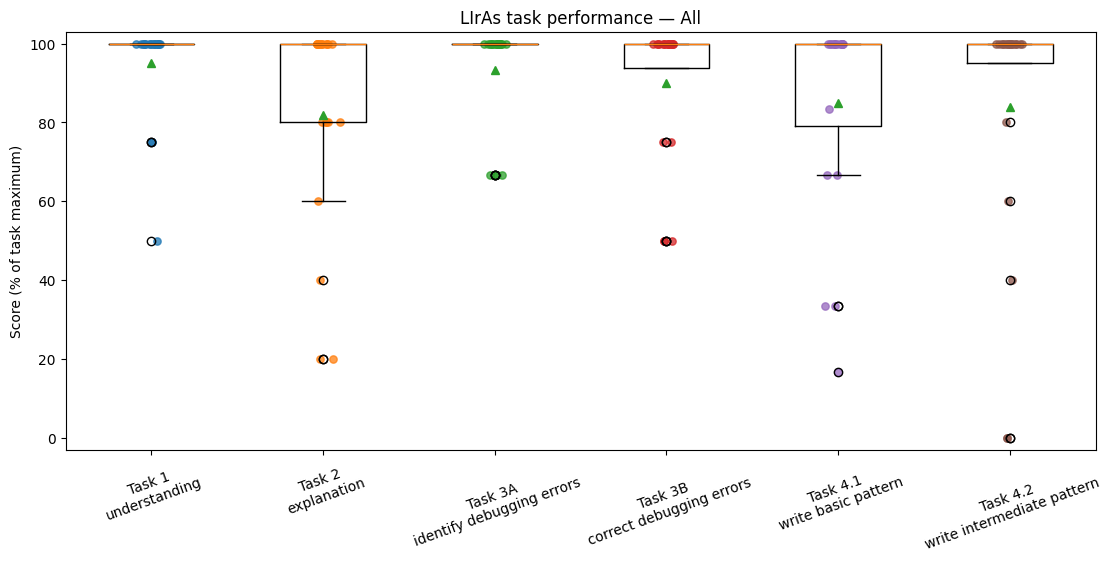

In [8]:
def plot_task_scores(df=analysis_df, cohort='All', normalize=True, t42_attempted_only=False, save_name=None):
    d = select_cohort(df, cohort)
    labels, data = [], []
    for label, (col, max_score) in PRIMARY_TASKS.items():
        dd = d
        if col == 'T4.2 total' and t42_attempted_only:
            dd = dd.loc[dd['T4.2 attempted']]
        x = pd.to_numeric(dd[col], errors='coerce').dropna().to_numpy(dtype=float)
        if normalize:
            x = 100*x/max_score
        labels.append(label.replace(' — ', '\n'))
        data.append(x)

    fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
    ax.boxplot(data, labels=labels, showmeans=True)
    rng = np.random.default_rng(42)
    for i, x in enumerate(data, start=1):
        jitter = rng.normal(0, 0.045, size=len(x))
        ax.scatter(np.full(len(x), i) + jitter, x, alpha=.75, s=28)
    ax.set_ylabel('Score (% of task maximum)' if normalize else 'Raw score')
    ax.set_title(f'LIrAs task performance — {cohort}')
    ax.tick_params(axis='x', labelrotation=20)
    if normalize:
        ax.set_ylim(-3, 103)
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=200, bbox_inches='tight')
    plt.show()

plot_task_scores(save_name='task_performance_all.png')

## 7. Interactive score explorer

If `ipywidgets` is installed, use the dropdowns to switch cohort and metric. Otherwise, call `score_dashboard(cohort='Known', metric='Overall performance')` manually.

In [9]:
SCORE_METRICS = OrderedDict([
    ('Overall performance', ('Overall raw', 17.0)),
    ('Task 1 — understanding', ('T1 total', 4.0)),
    ('Task 2 — explanation', ('T2 total', 2.5)),
    ('Task 3 — debugging total', ('T3 total', 5.0)),
    ('Task 3A — identify errors', ('T3A total', 3.0)),
    ('Task 3B — correct pattern', ('T3B total', 2.0)),
    ('Task 4.1 — basic writing', ('T4.1 total', 3.0)),
    ('Task 4.2 — intermediate writing', ('T4.2 total', 2.5)),
])


def score_dashboard(cohort='All', metric='Overall performance', t42_attempted_only=False):
    d = select_cohort(analysis_df, cohort)
    col, max_score = SCORE_METRICS[metric]
    if col == 'T4.2 total' and t42_attempted_only:
        d = d.loc[d['T4.2 attempted']]
    x = pd.to_numeric(d[col], errors='coerce').dropna()
    summary = pd.DataFrame({
        'n':[len(x)], 'mean':[x.mean()], 'sd':[x.std(ddof=1)], 'median':[x.median()],
        'Q1':[x.quantile(.25)], 'Q3':[x.quantile(.75)],
        'mean % max':[100*x.mean()/max_score], 'ceiling %':[100*x.eq(max_score).mean()]
    })
    display(summary.round(2))

    fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    vals = 100*x.to_numpy()/max_score
    ax.boxplot([vals], labels=[metric], showmeans=True)
    rng = np.random.default_rng(42)
    ax.scatter(1+rng.normal(0, .035, size=len(vals)), vals, alpha=.8)
    ax.set_ylim(-3,103)
    ax.set_ylabel('% of maximum score')
    ax.set_title(f'{metric} — {cohort}')
    plt.show()

if WIDGETS_AVAILABLE:
    cohort_w = widgets.Dropdown(options=['All','Known','Prolific'], value='All', description='Cohort:')
    metric_w = widgets.Dropdown(options=list(SCORE_METRICS.keys()), value='Overall performance', description='Metric:')
    attempt_w = widgets.Checkbox(value=False, description='T4.2 attempted only')
    out = widgets.interactive_output(score_dashboard, {
        'cohort':cohort_w, 'metric':metric_w, 't42_attempted_only':attempt_w
    })
    display(widgets.HBox([cohort_w, metric_w, attempt_w]), out)
else:
    print('ipywidgets is not installed. Example:')
    print("score_dashboard(cohort='All', metric='Overall performance')")

Output()

## 8. Known vs Prolific performance comparison

This table is intended primarily as a **sensitivity analysis for the pooling decision**. With `n=10` in each cohort, prioritize the effect size and the raw distributions over a binary significant/non-significant interpretation.

,Variable,Known n,Known median,Known mean,Prolific n,Prolific median,Prolific mean,Median difference (Known-Prolific),Rank-biserial effect,p,q (BH)
5,Task 4.2,10,2.500,2.500,10,2.250,1.700,0.250,0.50,0.015,0.104
4,Task 4.1,10,3.000,2.950,10,2.500,2.150,0.500,0.45,0.040,0.140
6,Overall performance (%),10,97.059,92.941,10,89.706,84.706,7.353,0.40,0.137,0.312
3,Task 3B,10,2.000,1.700,10,2.000,1.900,0.000,-0.28,0.178,0.312
2,Task 3A,10,3.000,2.700,10,3.000,2.900,0.000,-0.20,0.301,0.421
0,Task 1,10,4.000,3.900,10,4.000,3.700,0.000,0.11,0.543,0.633
1,Task 2,10,2.250,2.050,10,2.500,2.050,-0.250,-0.07,0.802,0.802


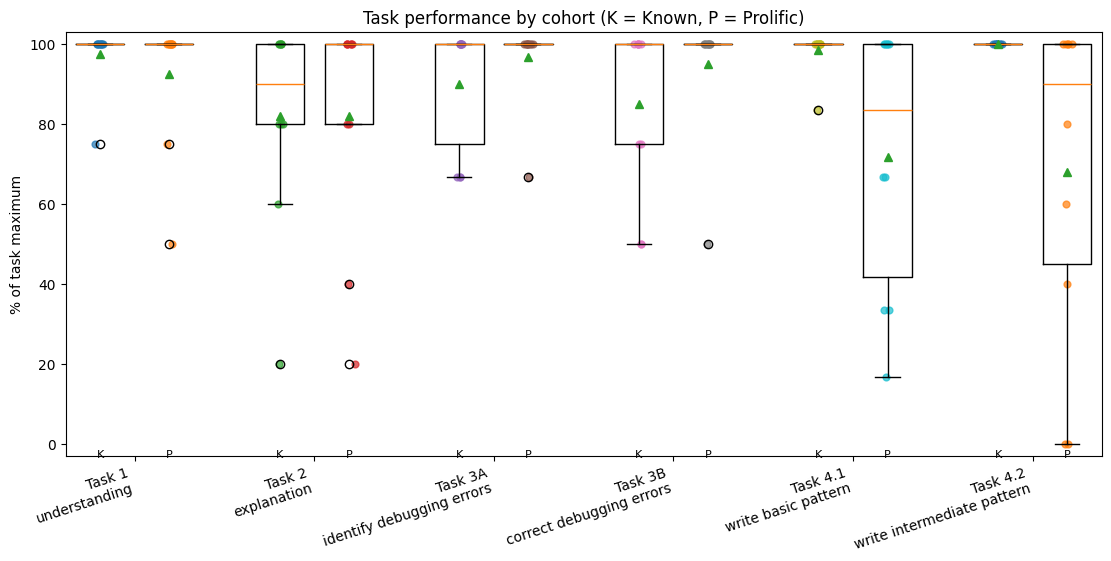

In [10]:
compare_vars = ['T1 total','T2 total','T3A total','T3B total','T4.1 total','T4.2 total','Overall raw pct']
compare_labels = {
    'T1 total':'Task 1', 'T2 total':'Task 2', 'T3A total':'Task 3A', 'T3B total':'Task 3B',
    'T4.1 total':'Task 4.1', 'T4.2 total':'Task 4.2', 'Overall raw pct':'Overall performance (%)'
}
cohort_performance = compare_two_cohorts(analysis_df, compare_vars, compare_labels)
display(cohort_performance.round(3))

# Normalized task distributions by cohort.
fig, ax = plt.subplots(figsize=(11,5.5), constrained_layout=True)
positions = []
plot_data = []
plot_labels = []
pos = 1
for label, (col, max_score) in PRIMARY_TASKS.items():
    for cohort in ['Known','Prolific']:
        vals = 100 * analysis_df.loc[analysis_df['Cohort'].eq(cohort), col].dropna().to_numpy(dtype=float) / max_score
        plot_data.append(vals)
        positions.append(pos)
        plot_labels.append(cohort[0])
        pos += 1
    pos += .6
ax.boxplot(plot_data, positions=positions, widths=.7, showmeans=True)
rng = np.random.default_rng(42)
for p, vals in zip(positions, plot_data):
    ax.scatter(np.full(len(vals), p)+rng.normal(0,.04,len(vals)), vals, alpha=.7, s=24)
centers=[]
pos=1
for _ in PRIMARY_TASKS:
    centers.append((pos+(pos+1))/2)
    pos += 2.6
ax.set_xticks(centers)
ax.set_xticklabels([k.replace(' — ','\n') for k in PRIMARY_TASKS], rotation=18, ha='right')
ax.set_ylim(-3,103)
ax.set_ylabel('% of task maximum')
ax.set_title('Task performance by cohort (K = Known, P = Prolific)')
for p, lab in zip(positions, plot_labels):
    ax.text(p, -1.5, lab, ha='center', va='top', fontsize=8)
fig.savefig(OUTPUT_DIR/'task_performance_by_cohort.png', dpi=200, bbox_inches='tight')
plt.show()

### T4.2 completion/attempt sensitivity

Two T4.2 responses are explicitly marked as non-attempts or misplaced answers. The primary analysis keeps the workbook scores exactly as entered (including zeros), because running out of time is itself part of observed task performance. This sensitivity view separates **completion/attempt rate** from **accuracy among those who attempted the task**.

In [11]:
# Attempt/completion rate by cohort.
attempt_tab = pd.crosstab(analysis_df['Cohort'], analysis_df['T4.2 attempted'])
display(attempt_tab)

# Fisher exact test for the 2x2 attempt table when both columns are present.
if set([False, True]).issubset(attempt_tab.columns):
    tab = attempt_tab.reindex(index=['Known','Prolific'], columns=[True,False], fill_value=0).to_numpy()
    odds, p_attempt = fisher_exact(tab)
    print(f'Fisher exact test for T4.2 attempt rate: p={p_attempt:.3f}, odds ratio={odds:.3f}')

# Score comparison among participants who actually attempted T4.2.
t42_attempted = analysis_df.loc[analysis_df['T4.2 attempted']].copy()
t42_attempted_compare = compare_two_cohorts(
    t42_attempted, ['T4.2 total'], labels={'T4.2 total':'Task 4.2 — attempted only'}
)
display(t42_attempted_compare.round(3))

T4.2 attempted,False,True
Cohort,,
Known,0,10
Prolific,2,8


Fisher exact test for T4.2 attempt rate: p=0.474, odds ratio=inf


,Variable,Known n,Known median,Known mean,Prolific n,Prolific median,Prolific mean,Median difference (Known-Prolific),Rank-biserial effect,p,q (BH)
0,Task 4.2 — attempted only,10,2.5,2.5,8,2.5,2.125,0.0,0.375,0.047,0.047


## 9. Item-level correctness

This is useful for identifying which language constructs caused errors even when task totals are near ceiling. Fisher's exact test is used for the binary item-by-cohort comparisons.

,Item,All correct %,Known correct %,Prolific correct %,Fisher p,Odds ratio,q (BH)
0,T1.1 — continuation behavior,90.0,90.0,90.0,1.0,1.000,1.0
1,T1.2 — until behavior,100.0,100.0,100.0,1.0,NaN,1.0
2,T1.3 — coordinated inspection,95.0,100.0,90.0,1.0,inf,1.0
3,T1.4 — restart scope,95.0,100.0,90.0,1.0,inf,1.0
4,T3A.1 — continuation error,85.0,80.0,90.0,1.0,0.444,1.0
5,T3A.2 — skip position,95.0,90.0,100.0,1.0,0.000,1.0
6,T3A.3 — restart predicate,100.0,100.0,100.0,1.0,NaN,1.0


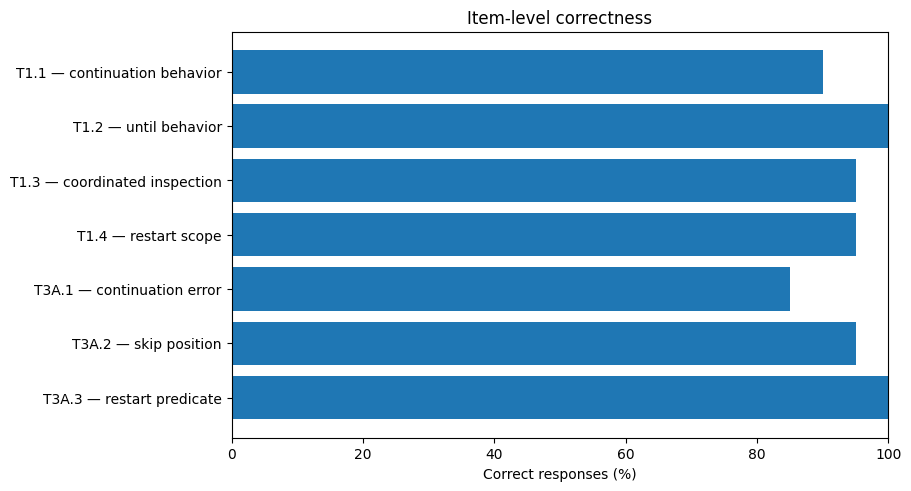

In [12]:
ITEMS = OrderedDict([
    ('T1.1 — continuation behavior','T1.1'),
    ('T1.2 — until behavior','T1.2'),
    ('T1.3 — coordinated inspection','T1.3'),
    ('T1.4 — restart scope','T1.4'),
    ('T3A.1 — continuation error','Err 1'),
    ('T3A.2 — skip position','Err 2'),
    ('T3A.3 — restart predicate','Err 3'),
])

rows=[]
for label,col in ITEMS.items():
    all_x = analysis_df[col].dropna()
    known = analysis_df.loc[analysis_df['Cohort'].eq('Known'), col].dropna().astype(int)
    prol = analysis_df.loc[analysis_df['Cohort'].eq('Prolific'), col].dropna().astype(int)
    table = [[known.sum(), len(known)-known.sum()], [prol.sum(), len(prol)-prol.sum()]]
    try:
        odds, p = fisher_exact(table)
    except Exception:
        odds, p = np.nan, np.nan
    rows.append({
        'Item':label,
        'All correct %':100*all_x.mean(),
        'Known correct %':100*known.mean(),
        'Prolific correct %':100*prol.mean(),
        'Fisher p':p,
        'Odds ratio':odds,
    })
item_table=pd.DataFrame(rows)
item_table['q (BH)']=bh_adjust(item_table['Fisher p'])
display(item_table.round(3))

fig, ax = plt.subplots(figsize=(9,4.8), constrained_layout=True)
y=np.arange(len(item_table))
ax.barh(y, item_table['All correct %'])
ax.set_yticks(y)
ax.set_yticklabels(item_table['Item'])
ax.set_xlim(0,100)
ax.set_xlabel('Correct responses (%)')
ax.set_title('Item-level correctness')
ax.invert_yaxis()
fig.savefig(OUTPUT_DIR/'item_correctness.png', dpi=200, bbox_inches='tight')
plt.show()

## 10. Background–performance associations

Spearman's rho is used because the background measures are ordinal and the score distributions are bounded. The table includes BH-adjusted q-values across the tested background × score combinations.

Because `N=20`, correlations can be unstable. Strong-looking coefficients should be inspected graphically and interpreted as exploratory.

In [13]:
CORR_TARGETS = OrderedDict([
    ('Overall performance', 'Overall raw pct'),
    ('Task 1', 'T1 total pct'),
    ('Task 2', 'T2 total pct'),
    ('Task 3A', 'T3A total pct'),
    ('Task 3B', 'T3B total pct'),
    ('Task 4.1', 'T4.1 total pct'),
    ('Task 4.2', 'T4.2 total pct'),
])


def spearman_table(df, predictors, targets, cohort='All'):
    d = select_cohort(df, cohort)
    rows=[]
    for p_label,p_col in predictors.items():
        for t_label,t_col in targets.items():
            tmp=d[[p_col,t_col]].dropna()
            if len(tmp) < 4 or tmp[p_col].nunique() < 2 or tmp[t_col].nunique() < 2:
                rho,p=np.nan,np.nan
            else:
                rho,p=spearmanr(tmp[p_col], tmp[t_col])
            rows.append({'Predictor':p_label,'Outcome':t_label,'n':len(tmp),'rho':rho,'p':p})
    out=pd.DataFrame(rows)
    out['q (BH)']=bh_adjust(out['p'])
    return out.sort_values(['q (BH)','p'], na_position='last')

background_corr = spearman_table(analysis_df, BACKGROUND_ORDINAL, CORR_TARGETS)
display(background_corr.round(3))

print('\nLargest absolute correlations (regardless of p-value):')
display(background_corr.assign(abs_rho=background_corr['rho'].abs()).sort_values('abs_rho', ascending=False).head(12).drop(columns='abs_rho').round(3))

,Predictor,Outcome,n,rho,p,q (BH)
18,Modeling-notation experience,Task 3B,20,0.471,0.036,0.503
29,Formal-methods experience,Task 1,20,0.458,0.042,0.503
67,Formal/modeling experience index,Task 3B,20,0.454,0.044,0.503
14,Modeling-notation experience,Overall performance,20,0.443,0.051,0.503
22,Uppaal/automata experience,Task 1,20,0.423,0.063,0.503
...,...,...,...,...,...,...
26,Uppaal/automata experience,Task 4.1,20,0.046,0.847,0.898
8,Textual DSL experience,Task 1,20,-0.025,0.918,0.952
10,Textual DSL experience,Task 3A,20,-0.023,0.924,0.952
21,Uppaal/automata experience,Overall performance,20,0.014,0.954,0.968



Largest absolute correlations (regardless of p-value):


,Predictor,Outcome,n,rho,p,q (BH)
18,Modeling-notation experience,Task 3B,20,0.471,0.036,0.503
29,Formal-methods experience,Task 1,20,0.458,0.042,0.503
67,Formal/modeling experience index,Task 3B,20,0.454,0.044,0.503
14,Modeling-notation experience,Overall performance,20,0.443,0.051,0.503
22,Uppaal/automata experience,Task 1,20,0.423,0.063,0.503
55,English technical reading,Task 4.2,20,-0.415,0.069,0.503
11,Textual DSL experience,Task 3B,20,0.401,0.079,0.503
60,Prior technical experience index,Task 3B,20,0.391,0.088,0.503
53,English technical reading,Task 3B,20,0.382,0.096,0.503
58,Prior technical experience index,Task 2,20,-0.378,0.100,0.503


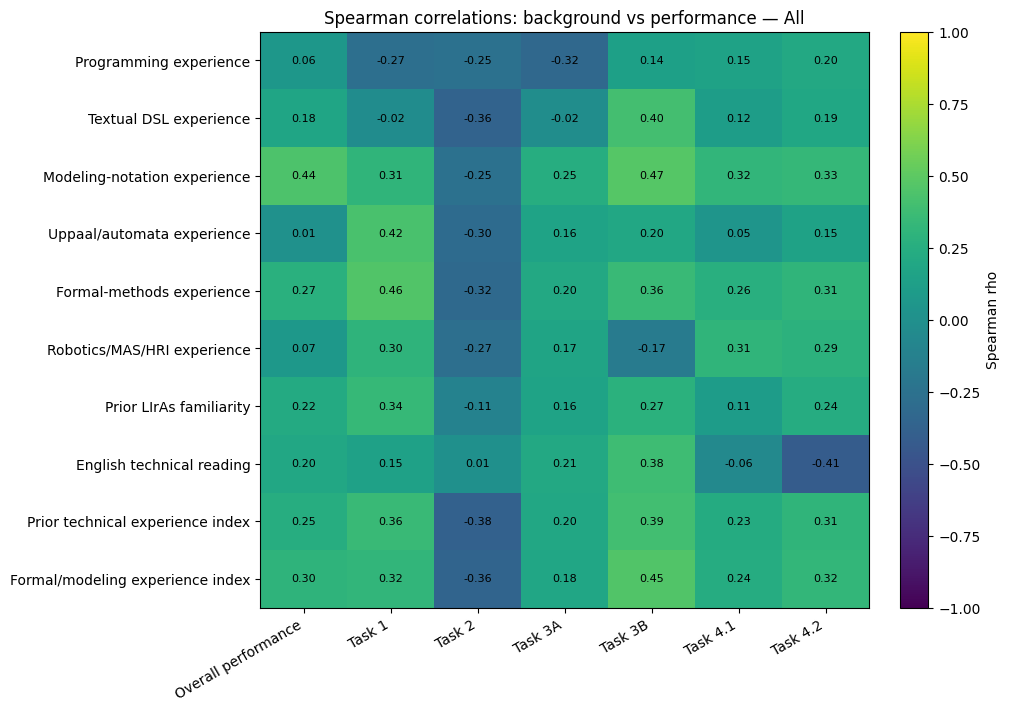

In [14]:
def correlation_heatmap(df=analysis_df, cohort='All'):
    d = select_cohort(df, cohort)
    predictors=list(BACKGROUND_ORDINAL.items())
    targets=list(CORR_TARGETS.items())
    mat=np.full((len(predictors),len(targets)),np.nan)
    for i,(pl,pc) in enumerate(predictors):
        for j,(tl,tc) in enumerate(targets):
            tmp=d[[pc,tc]].dropna()
            if len(tmp)>=4 and tmp[pc].nunique()>1 and tmp[tc].nunique()>1:
                mat[i,j]=spearmanr(tmp[pc],tmp[tc]).statistic
    fig,ax=plt.subplots(figsize=(10,7), constrained_layout=True)
    im=ax.imshow(mat, aspect='auto', vmin=-1, vmax=1)
    ax.set_xticks(range(len(targets)))
    ax.set_xticklabels([x[0] for x in targets], rotation=30, ha='right')
    ax.set_yticks(range(len(predictors)))
    ax.set_yticklabels([x[0] for x in predictors])
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if np.isfinite(mat[i,j]):
                ax.text(j,i,f'{mat[i,j]:.2f}',ha='center',va='center',fontsize=8)
    ax.set_title(f'Spearman correlations: background vs performance — {cohort}')
    fig.colorbar(im, ax=ax, label='Spearman rho')
    plt.show()

correlation_heatmap()

### Interactive correlation explorer

This plots one ordered background variable against one score. Points are jittered slightly because many participants share the same ordinal value.

In [15]:
def background_score_plot(cohort='All', background='Prior technical experience index', outcome='Overall performance'):
    d=select_cohort(analysis_df, cohort)
    xcol=BACKGROUND_ORDINAL[background]
    ycol=CORR_TARGETS[outcome]
    tmp=d[[xcol,ycol]].dropna().copy()
    if len(tmp)>=4 and tmp[xcol].nunique()>1 and tmp[ycol].nunique()>1:
        rho,p=spearmanr(tmp[xcol],tmp[ycol])
    else:
        rho,p=np.nan,np.nan
    display(pd.DataFrame({'n':[len(tmp)],'Spearman rho':[rho],'p':[p]}).round(3))
    fig,ax=plt.subplots(figsize=(6.5,4.3), constrained_layout=True)
    rng=np.random.default_rng(42)
    ax.scatter(tmp[xcol]+rng.normal(0,.025,len(tmp)), tmp[ycol], alpha=.8)
    ax.set_xlabel(background)
    ax.set_ylabel(outcome + ' (%)')
    ax.set_title(f'{background} vs {outcome} — {cohort}')
    plt.show()

if WIDGETS_AVAILABLE:
    c=widgets.Dropdown(options=['All','Known','Prolific'], value='All', description='Cohort:')
    b=widgets.Dropdown(options=list(BACKGROUND_ORDINAL.keys()), value='Prior technical experience index', description='Background:')
    o=widgets.Dropdown(options=list(CORR_TARGETS.keys()), value='Overall performance', description='Outcome:')
    out=widgets.interactive_output(background_score_plot, {'cohort':c,'background':b,'outcome':o})
    display(widgets.VBox([widgets.HBox([c,o]),b]),out)
else:
    print("Example: background_score_plot('All', 'Programming experience', 'Overall performance')")

Output()

## 11. Feedback and user perception

The LIrAs and tutorial items are treated as ordered Likert responses. The most useful summaries for a paper are usually:

- response distribution per item;
- proportion of `Agree + Strongly agree`;
- mental-effort distribution;
- frequency of the aspect identified as most difficult.

In [16]:
LIKERT_ORDER=['Strongly disagree','Disagree','Neither agree nor disagree','Agree','Strongly agree']


def favorable_feedback_table(df, columns, cohort='All'):
    d=select_cohort(df, cohort)
    rows=[]
    for c in columns:
        s=d[c].dropna()
        rows.append({
            'Item':c,
            'n':len(s),
            'Median (1-5)':s.map(likert_map).median(),
            'Agree + strongly agree %':100*s.isin(['Agree','Strongly agree']).mean(),
            'Strongly agree %':100*s.eq('Strongly agree').mean(),
            'Neutral %':100*s.eq('Neither agree nor disagree').mean(),
            'Disagree %':100*s.isin(['Disagree','Strongly disagree']).mean(),
        })
    return pd.DataFrame(rows)

print('LIrAs perception:')
display(favorable_feedback_table(analysis_df, LIRAS_FEEDBACK).round(1))
print('\nTutorial perception:')
display(favorable_feedback_table(analysis_df, TUTORIAL_FEEDBACK).round(1))

LIrAs perception:


,Item,n,Median (1-5),Agree + strongly agree %,Strongly agree %,Neutral %,Disagree %
0,LIrAs: Syntax,20,4.0,90.0,30.0,10.0,0.0
1,LIrAs: Scenario -> specification,20,4.0,70.0,35.0,25.0,5.0
2,LIrAs: Synchronization,20,4.0,80.0,35.0,15.0,5.0
3,LIrAs: Continuations,20,4.0,75.0,35.0,20.0,5.0
4,LIrAs: Conditional constructs,20,4.0,85.0,30.0,15.0,0.0
5,LIrAs: Skip/restart,20,4.0,65.0,15.0,30.0,5.0
6,LIrAs: Confidence,20,4.0,60.0,20.0,30.0,10.0



Tutorial perception:


,Item,n,Median (1-5),Agree + strongly agree %,Strongly agree %,Neutral %,Disagree %
0,Tutorial: Clarity,20,4.0,90.0,35.0,10.0,0.0
1,Tutorial: Actions/predicates/parameters,20,4.0,90.0,45.0,10.0,0.0
2,Tutorial: Examples,20,5.0,95.0,70.0,5.0,0.0
3,Tutorial: Sufficient information,20,4.0,95.0,45.0,5.0,0.0


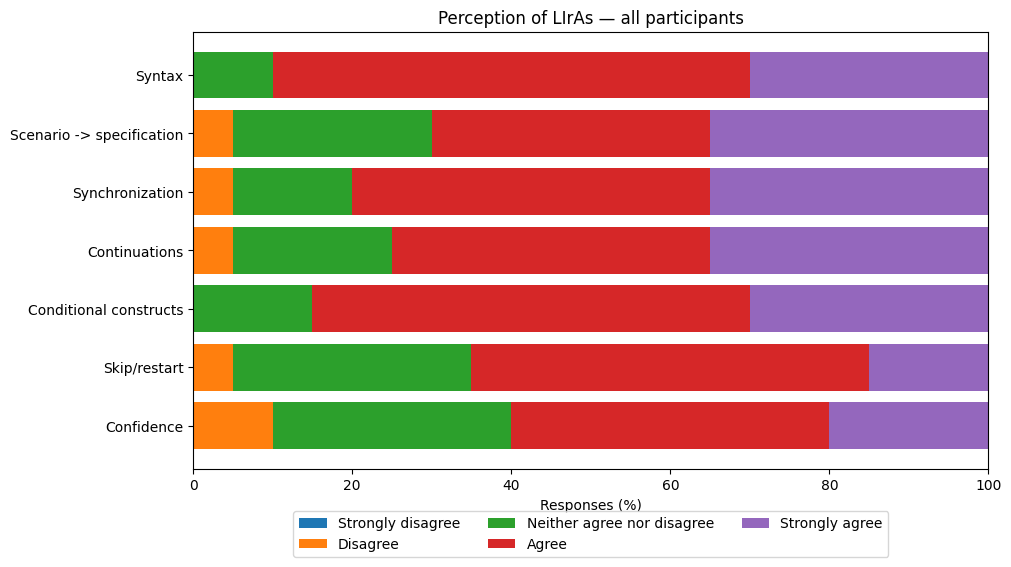

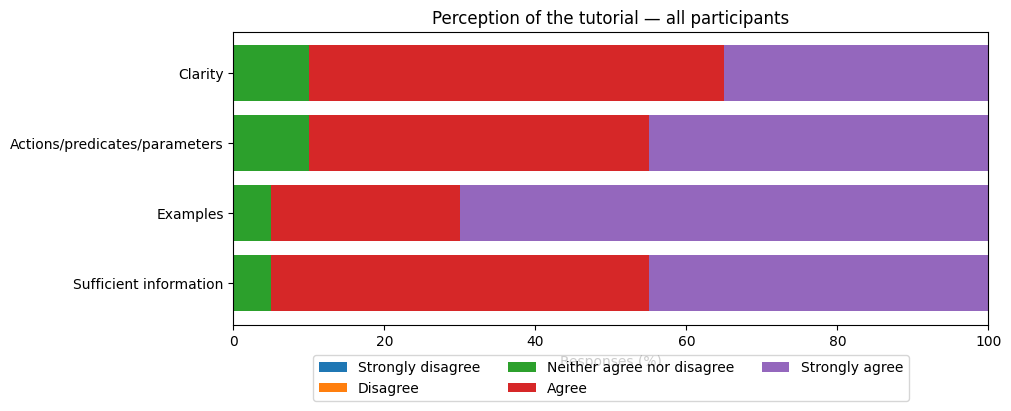

In [17]:
def plot_likert(df, columns, cohort='All', title=None, save_name=None):
    d=select_cohort(df, cohort)
    pct=[]
    for c in columns:
        vc=d[c].value_counts(normalize=True).reindex(LIKERT_ORDER, fill_value=0)*100
        pct.append(vc.values)
    pct=np.asarray(pct)
    fig,ax=plt.subplots(figsize=(10, max(4, .58*len(columns)+1.5)), constrained_layout=True)
    left=np.zeros(len(columns))
    y=np.arange(len(columns))
    for j,cat in enumerate(LIKERT_ORDER):
        ax.barh(y,pct[:,j],left=left,label=cat)
        left += pct[:,j]
    ax.set_yticks(y)
    ax.set_yticklabels([c.replace('LIrAs: ','').replace('Tutorial: ','') for c in columns])
    ax.set_xlim(0,100)
    ax.set_xlabel('Responses (%)')
    ax.set_title(title or f'Likert responses — {cohort}')
    ax.legend(loc='upper center', bbox_to_anchor=(.5,-.08), ncol=3)
    ax.invert_yaxis()
    if save_name:
        fig.savefig(OUTPUT_DIR/save_name,dpi=200,bbox_inches='tight')
    plt.show()

plot_likert(analysis_df, LIRAS_FEEDBACK, title='Perception of LIrAs — all participants', save_name='feedback_liras_likert.png')
plot_likert(analysis_df, TUTORIAL_FEEDBACK, title='Perception of the tutorial — all participants', save_name='feedback_tutorial_likert.png')

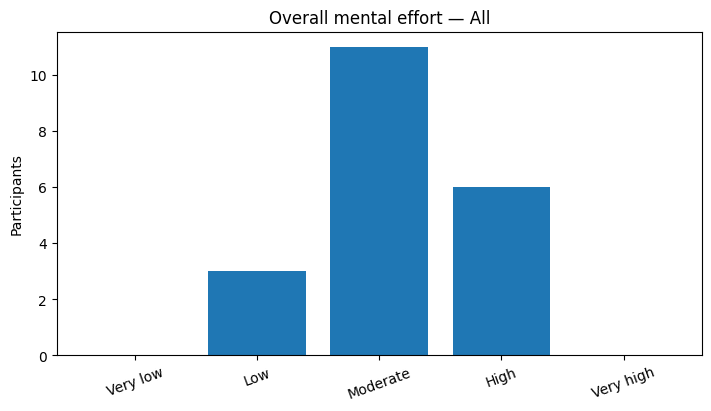

,n
Mental effort,
Very low,0
Low,3
Moderate,11
High,6
Very high,0


In [18]:
def plot_mental_effort(df=analysis_df, cohort='All', save_name=None):
    d=select_cohort(df, cohort)
    order=['Very low','Low','Moderate','High','Very high']
    labels=d['Mental effort'].dropna().astype(str).str.split('—').str[0].str.strip()
    counts=labels.value_counts().reindex(order,fill_value=0)
    fig,ax=plt.subplots(figsize=(7,4), constrained_layout=True)
    ax.bar(counts.index, counts.values)
    ax.set_ylabel('Participants')
    ax.set_title(f'Overall mental effort — {cohort}')
    ax.tick_params(axis='x', rotation=20)
    if save_name:
        fig.savefig(OUTPUT_DIR/save_name,dpi=200,bbox_inches='tight')
    plt.show()
    return counts.to_frame('n')

mental_counts=plot_mental_effort(save_name='mental_effort.png')
display(mental_counts)

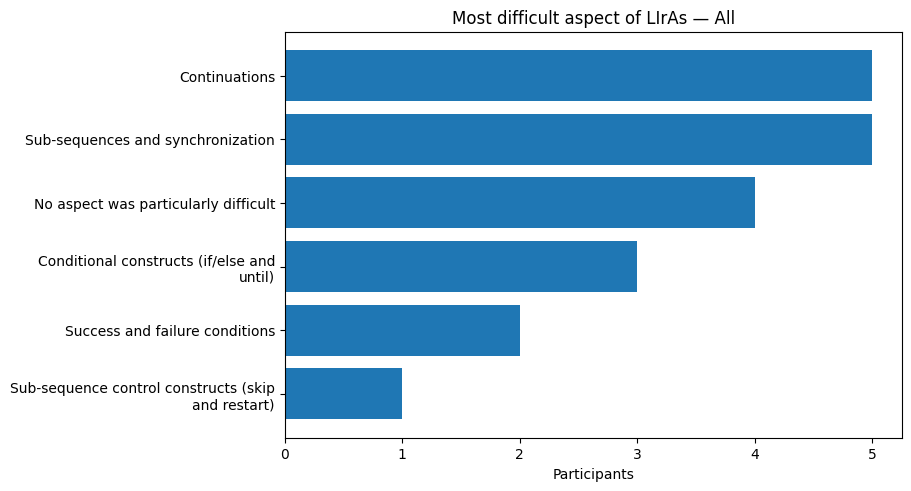

,n
Most difficult aspect,
Sub-sequences and synchronization,5
Continuations,5
No aspect was particularly difficult,4
Conditional constructs (if/else and until),3
Success and failure conditions,2
Sub-sequence control constructs (skip and restart),1


In [19]:
def plot_difficult_aspects(df=analysis_df, cohort='All', save_name=None):
    d=select_cohort(df, cohort)
    counts=d['Most difficult aspect'].value_counts(ascending=True)
    fig,ax=plt.subplots(figsize=(9,4.8), constrained_layout=True)
    ax.barh(range(len(counts)),counts.values)
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels([textwrap.fill(x, 38) for x in counts.index])
    ax.set_xlabel('Participants')
    ax.set_title(f'Most difficult aspect of LIrAs — {cohort}')
    if save_name:
        fig.savefig(OUTPUT_DIR/save_name,dpi=200,bbox_inches='tight')
    plt.show()
    return counts.to_frame('n').sort_values('n',ascending=False)

aspect_counts=plot_difficult_aspects(save_name='most_difficult_aspect.png')
display(aspect_counts)

### Interactive feedback explorer

Choose a cohort and one of the main feedback views. If widgets are unavailable, call `feedback_dashboard(...)` directly.

In [20]:
def feedback_dashboard(cohort='All', view='LIrAs perception'):
    if view == 'LIrAs perception':
        display(favorable_feedback_table(analysis_df,LIRAS_FEEDBACK,cohort).round(1))
        plot_likert(analysis_df,LIRAS_FEEDBACK,cohort,title=f'LIrAs perception — {cohort}')
    elif view == 'Tutorial perception':
        display(favorable_feedback_table(analysis_df,TUTORIAL_FEEDBACK,cohort).round(1))
        plot_likert(analysis_df,TUTORIAL_FEEDBACK,cohort,title=f'Tutorial perception — {cohort}')
    elif view == 'Mental effort':
        display(plot_mental_effort(analysis_df,cohort))
    elif view == 'Most difficult aspect':
        display(plot_difficult_aspects(analysis_df,cohort))

if WIDGETS_AVAILABLE:
    c=widgets.Dropdown(options=['All','Known','Prolific'],value='All',description='Cohort:')
    v=widgets.Dropdown(options=['LIrAs perception','Tutorial perception','Mental effort','Most difficult aspect'],value='LIrAs perception',description='View:')
    out=widgets.interactive_output(feedback_dashboard,{'cohort':c,'view':v})
    display(widgets.HBox([c,v]),out)
else:
    print("Example: feedback_dashboard('Prolific', 'Tutorial perception')")

Output()

## 12. Cohort differences in feedback

This is exploratory. It can be useful if the two recruitment channels produce noticeably different perceptions even when task performance is similar.

In [21]:
feedback_numeric = OrderedDict([
    ('Mental effort','Mental effort ord'),
    *[(c,c+' ord') for c in LIRAS_FEEDBACK],
    *[(c,c+' ord') for c in TUTORIAL_FEEDBACK],
])
feedback_cohort_comparison=compare_two_cohorts(
    analysis_df, list(feedback_numeric.values()), labels={v:k for k,v in feedback_numeric.items()}
)
display(feedback_cohort_comparison.round(3))

,Variable,Known n,Known median,Known mean,Prolific n,Prolific median,Prolific mean,Median difference (Known-Prolific),Rank-biserial effect,p,q (BH)
11,Tutorial: Sufficient information,10,5.0,4.9,10,4.0,3.9,1.0,0.91,0.000,0.001
9,Tutorial: Actions/predicates/parameters,10,5.0,4.8,10,4.0,3.9,1.0,0.74,0.002,0.011
0,Mental effort,10,3.0,2.7,10,4.0,3.6,-1.0,-0.72,0.003,0.011
1,LIrAs: Syntax,10,5.0,4.6,10,4.0,3.8,1.0,0.68,0.004,0.011
4,LIrAs: Continuations,10,5.0,4.6,10,3.5,3.5,1.5,0.70,0.006,0.014
2,LIrAs: Scenario -> specification,10,5.0,4.5,10,3.5,3.5,1.5,0.62,0.015,0.027
8,Tutorial: Clarity,10,5.0,4.6,10,4.0,3.9,1.0,0.58,0.015,0.027
3,LIrAs: Synchronization,10,5.0,4.5,10,4.0,3.7,1.0,0.54,0.031,0.047
10,Tutorial: Examples,10,5.0,4.9,10,4.5,4.4,0.5,0.41,0.059,0.074
7,LIrAs: Confidence,10,4.0,4.1,10,3.0,3.3,1.0,0.48,0.061,0.074


## 13. Perception–performance associations

These analyses can reveal, for example, whether participants who report higher confidence also achieve higher scores, or whether higher mental effort accompanies lower performance. Again, with `N=20`, these are exploratory rather than confirmatory.

In [22]:
PERCEPTION_PREDICTORS=OrderedDict([
    ('Mental effort','Mental effort ord'),
    ('LIrAs syntax clarity','LIrAs: Syntax ord'),
    ('Scenario -> specification clarity','LIrAs: Scenario -> specification ord'),
    ('Synchronization clarity','LIrAs: Synchronization ord'),
    ('Continuation clarity','LIrAs: Continuations ord'),
    ('Conditional constructs clarity','LIrAs: Conditional constructs ord'),
    ('Skip/restart clarity','LIrAs: Skip/restart ord'),
    ('Confidence','LIrAs: Confidence ord'),
    ('Tutorial clarity','Tutorial: Clarity ord'),
    ('Tutorial sufficient information','Tutorial: Sufficient information ord'),
])

perception_corr=spearman_table(analysis_df,PERCEPTION_PREDICTORS,CORR_TARGETS)
display(perception_corr.round(3))

print('\nLargest absolute perception–performance correlations:')
display(perception_corr.assign(abs_rho=perception_corr['rho'].abs()).sort_values('abs_rho',ascending=False).head(12).drop(columns='abs_rho').round(3))

,Predictor,Outcome,n,rho,p,q (BH)
12,LIrAs syntax clarity,Task 4.1,20,0.607,0.005,0.305
25,Synchronization clarity,Task 3B,20,-0.548,0.012,0.305
69,Tutorial sufficient information,Task 4.2,20,0.544,0.013,0.305
7,LIrAs syntax clarity,Overall performance,20,0.510,0.022,0.379
45,Skip/restart clarity,Task 3A,20,0.459,0.042,0.441
...,...,...,...,...,...,...
49,Confidence,Overall performance,20,0.026,0.915,0.956
10,LIrAs syntax clarity,Task 3A,20,-0.025,0.917,0.956
54,Confidence,Task 4.1,20,-0.021,0.928,0.956
50,Confidence,Task 1,20,0.017,0.945,0.958



Largest absolute perception–performance correlations:


,Predictor,Outcome,n,rho,p,q (BH)
12,LIrAs syntax clarity,Task 4.1,20,0.607,0.005,0.305
25,Synchronization clarity,Task 3B,20,-0.548,0.012,0.305
69,Tutorial sufficient information,Task 4.2,20,0.544,0.013,0.305
7,LIrAs syntax clarity,Overall performance,20,0.510,0.022,0.379
45,Skip/restart clarity,Task 3A,20,0.459,0.042,0.441
68,Tutorial sufficient information,Task 4.1,20,0.457,0.043,0.441
63,Tutorial sufficient information,Overall performance,20,0.440,0.052,0.441
42,Skip/restart clarity,Overall performance,20,0.432,0.057,0.441
24,Synchronization clarity,Task 3A,20,-0.420,0.065,0.441
13,LIrAs syntax clarity,Task 4.2,20,0.410,0.073,0.441


## 14. Open feedback comments

The open comments are intentionally **not** automatically scored or sentiment-classified. With only 20 participants, a small manual thematic coding is more defensible and more informative than an opaque NLP score.

In [23]:
open_comments=analysis_df.loc[
    analysis_df['Open feedback'].notna() & analysis_df['Open feedback'].astype(str).str.strip().ne(''),
    ['Blind ID','Cohort','Open feedback']
].reset_index(drop=True)
print(f'Non-empty open comments: {len(open_comments)}')
display(open_comments)

Non-empty open comments: 15


,Blind ID,Cohort,Open feedback
0,S001,Known,"I didn't like having to renumber and check every step of every agent when adding a new one in the middle of others, in more complex scen..."
1,S003,Prolific,Its hard to write it from scratch because its too loose.
2,S004,Known,"if/else is unintuitive, it follows different rules than the typical code construct. Perhaps I'd change its name"
3,S006,Prolific,Clearer way to understand sequences
4,S008,Prolific,Having atleast 2 examples for each concept would be more useful.
5,S009,Known,Everything is clear and simple. My only comment is I would include actions and predicates into the declarations.
6,S010,Prolific,"Make it more clear when agents have to wait for each other and when they can work independently.\nMake things like continuations, if/els..."
7,S011,Known,"There seemed to be multiple ways to define sequences because one sequence can hold multiple actions, but one can also define sequence co..."
8,S012,Prolific,Better syntax for continautions- range numbers like 1-2 get confusing when tracking multiple steps -- explicit KW like 'background' or '...
9,S013,Prolific,provide more complex visual examples for multi agent continuations


## 15. Compact paper-candidate summaries

This section collects the outputs most likely to be useful when deciding what enters the paper. It does **not** automatically decide what is important; it surfaces effect sizes, adjusted p-values, ceiling effects, and favorable feedback rates.

In [24]:
# Performance table likely to be useful in the paper.
paper_performance = task_descriptives(analysis_df)[[
    'Task','n','Mean','SD','Median','Q1','Q3','Mean % of max','At ceiling %'
]].copy()
print('Performance summary')
display(paper_performance.round(2))

# Cohort differences sorted by adjusted p-value, with effect sizes.
print('\nCohort sensitivity analysis')
display(cohort_performance.round(3))

# Feedback favorable rates.
paper_feedback=pd.concat([
    favorable_feedback_table(analysis_df,LIRAS_FEEDBACK).assign(Group='LIrAs'),
    favorable_feedback_table(analysis_df,TUTORIAL_FEEDBACK).assign(Group='Tutorial')
],ignore_index=True)
print('\nFeedback summary')
display(paper_feedback[['Group','Item','n','Median (1-5)','Agree + strongly agree %','Neutral %','Disagree %']].round(1))

# Strong exploratory associations after multiple-testing correction, plus large effects even if q is not small.
interesting_background = background_corr.loc[
    (background_corr['q (BH)'] < .10) | (background_corr['rho'].abs() >= .50)
].copy()
print('\nBackground associations worth inspecting (q < .10 OR |rho| >= .50)')
display(interesting_background.round(3))

interesting_perception = perception_corr.loc[
    (perception_corr['q (BH)'] < .10) | (perception_corr['rho'].abs() >= .50)
].copy()
print('\nPerception associations worth inspecting (q < .10 OR |rho| >= .50)')
display(interesting_perception.round(3))

Performance summary


,Task,n,Mean,SD,Median,Q1,Q3,Mean % of max,At ceiling %
0,Task 1 — understanding,20,3.80,0.52,4.0,4.00,4.0,95.00,85.0
1,Task 2 — explanation,20,2.05,0.67,2.5,2.00,2.5,82.00,55.0
2,Task 3A — identify debugging errors,20,2.80,0.41,3.0,3.00,3.0,93.33,80.0
3,Task 3B — correct debugging errors,20,1.80,0.38,2.0,1.88,2.0,90.00,75.0
4,Task 4.1 — write basic pattern,20,2.55,0.81,3.0,2.38,3.0,85.00,70.0
5,Task 4.2 — write intermediate pattern,20,2.10,0.82,2.5,2.38,2.5,84.00,75.0



Cohort sensitivity analysis


,Variable,Known n,Known median,Known mean,Prolific n,Prolific median,Prolific mean,Median difference (Known-Prolific),Rank-biserial effect,p,q (BH)
5,Task 4.2,10,2.500,2.500,10,2.250,1.700,0.250,0.50,0.015,0.104
4,Task 4.1,10,3.000,2.950,10,2.500,2.150,0.500,0.45,0.040,0.140
6,Overall performance (%),10,97.059,92.941,10,89.706,84.706,7.353,0.40,0.137,0.312
3,Task 3B,10,2.000,1.700,10,2.000,1.900,0.000,-0.28,0.178,0.312
2,Task 3A,10,3.000,2.700,10,3.000,2.900,0.000,-0.20,0.301,0.421
0,Task 1,10,4.000,3.900,10,4.000,3.700,0.000,0.11,0.543,0.633
1,Task 2,10,2.250,2.050,10,2.500,2.050,-0.250,-0.07,0.802,0.802



Feedback summary


,Group,Item,n,Median (1-5),Agree + strongly agree %,Neutral %,Disagree %
0,LIrAs,LIrAs: Syntax,20,4.0,90.0,10.0,0.0
1,LIrAs,LIrAs: Scenario -> specification,20,4.0,70.0,25.0,5.0
2,LIrAs,LIrAs: Synchronization,20,4.0,80.0,15.0,5.0
3,LIrAs,LIrAs: Continuations,20,4.0,75.0,20.0,5.0
4,LIrAs,LIrAs: Conditional constructs,20,4.0,85.0,15.0,0.0
5,LIrAs,LIrAs: Skip/restart,20,4.0,65.0,30.0,5.0
6,LIrAs,LIrAs: Confidence,20,4.0,60.0,30.0,10.0
7,Tutorial,Tutorial: Clarity,20,4.0,90.0,10.0,0.0
8,Tutorial,Tutorial: Actions/predicates/parameters,20,4.0,90.0,10.0,0.0
9,Tutorial,Tutorial: Examples,20,5.0,95.0,5.0,0.0



Background associations worth inspecting (q < .10 OR |rho| >= .50)


,Predictor,Outcome,n,rho,p,q (BH)



Perception associations worth inspecting (q < .10 OR |rho| >= .50)


,Predictor,Outcome,n,rho,p,q (BH)
12,LIrAs syntax clarity,Task 4.1,20,0.607,0.005,0.305
25,Synchronization clarity,Task 3B,20,-0.548,0.012,0.305
69,Tutorial sufficient information,Task 4.2,20,0.544,0.013,0.305
7,LIrAs syntax clarity,Overall performance,20,0.510,0.022,0.379


## 16. Export analysis-ready tables

The cell below writes clean CSV files and the figures generated above into `liras_analysis_outputs/`. These are derived artifacts only; the original scoring workbook remains unchanged.

In [25]:
export_df = analysis_df.copy()
export_df.to_csv(OUTPUT_DIR/'participant_analysis_dataset.csv', index=False)
paper_performance.to_csv(OUTPUT_DIR/'task_descriptives.csv', index=False)
cohort_performance.to_csv(OUTPUT_DIR/'cohort_performance_comparison.csv', index=False)
background_comp.to_csv(OUTPUT_DIR/'cohort_background_comparison.csv', index=False)
item_table.to_csv(OUTPUT_DIR/'item_level_correctness.csv', index=False)
background_corr.to_csv(OUTPUT_DIR/'background_performance_correlations.csv', index=False)
feedback_cohort_comparison.to_csv(OUTPUT_DIR/'cohort_feedback_comparison.csv', index=False)
perception_corr.to_csv(OUTPUT_DIR/'perception_performance_correlations.csv', index=False)
paper_feedback.to_csv(OUTPUT_DIR/'feedback_summary.csv', index=False)
open_comments.to_csv(OUTPUT_DIR/'open_feedback_comments.csv', index=False)

print('Exported files:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(' -', p.name)

Exported files:
 - .DS_Store
 - background_performance_correlations.csv
 - cohort_background_comparison.csv
 - cohort_feedback_comparison.csv
 - cohort_performance_comparison.csv
 - feedback_liras_likert.png
 - feedback_liras_likert_paper.pdf
 - feedback_liras_likert_paper.png
 - feedback_summary.csv
 - feedback_tutorial_likert.png
 - feedback_tutorial_likert_paper.pdf
 - feedback_tutorial_likert_paper.png
 - item_correctness.png
 - item_level_correctness.csv
 - mental_effort.png
 - most_difficult_aspect.png
 - open_feedback_comments.csv
 - participant_analysis_dataset.csv
 - perception_performance_correlations.csv
 - task_descriptives.csv
 - task_performance_all.png
 - task_performance_by_cohort.png


## 17. Interpretation checklist for the paper

When selecting results for the manuscript, the following order is usually the most defensible:

1. **Primary:** task-performance descriptives for the full sample, because these directly address whether users can understand and use LIrAs after a short tutorial.
2. **Primary:** mental effort and LIrAs/tutorial perception summaries.
3. **Diagnostic:** item-level errors and “most difficult aspect” to explain *where* difficulties arose.
4. **Sensitivity:** Known vs Prolific comparison. If distributions and effect sizes are similar, the pooled analysis can remain primary while the cohort comparison is reported briefly or in supplementary material. If there are material differences, report them explicitly rather than hiding them in the aggregate.
5. **Exploratory:** background–performance and perception–performance correlations. With only 20 participants, report only associations that are both substantively interpretable and reasonably robust; avoid presenting a large correlation table as confirmatory evidence.
6. **Qualitative:** open comments can support or contextualize quantitative findings after a small manual thematic coding.

A non-significant p-value with 10 participants per cohort does **not** establish equivalence between cohorts. Examine effect sizes and distributions as well.


Likert counts — cohort: All


,Strongly disagree,Disagree,Neither agree nor disagree,Agree,Strongly agree
Item,,,,,
Syntax clarity,0,0,2,12,6
Scenario-to-specification ease,0,1,5,7,7
Synchronization clarity,0,1,3,9,7
Continuation clarity,0,1,4,8,7
Conditional construct clarity,0,0,3,11,6
Skip/restart predictability,0,1,6,10,3
Specification confidence,0,2,6,8,4



Likert percentages — cohort: All


,Strongly disagree,Disagree,Neither agree nor disagree,Agree,Strongly agree
Item,,,,,
Syntax clarity,0.0,0.0,10.0,60.0,30.0
Scenario-to-specification ease,0.0,5.0,25.0,35.0,35.0
Synchronization clarity,0.0,5.0,15.0,45.0,35.0
Continuation clarity,0.0,5.0,20.0,40.0,35.0
Conditional construct clarity,0.0,0.0,15.0,55.0,30.0
Skip/restart predictability,0.0,5.0,30.0,50.0,15.0
Specification confidence,0.0,10.0,30.0,40.0,20.0


Saved PNG: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/liras_analysis_outputs/feedback_liras_likert_paper.png
Saved PDF: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/liras_analysis_outputs/feedback_liras_likert_paper.pdf


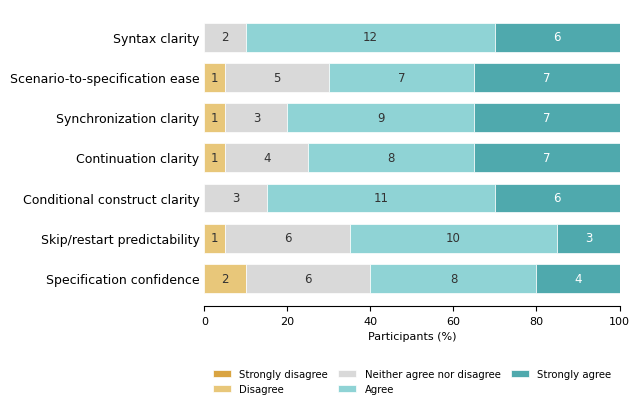


Likert counts — cohort: All


,Strongly disagree,Disagree,Neither agree nor disagree,Agree,Strongly agree
Item,,,,,
Tutorial clarity,0,0,2,11,7
"Actions, predicates and parameters",0,0,2,9,9
Example usefulness,0,0,1,5,14
Information sufficiency,0,0,1,10,9



Likert percentages — cohort: All


,Strongly disagree,Disagree,Neither agree nor disagree,Agree,Strongly agree
Item,,,,,
Tutorial clarity,0.0,0.0,10.0,55.0,35.0
"Actions, predicates and parameters",0.0,0.0,10.0,45.0,45.0
Example usefulness,0.0,0.0,5.0,25.0,70.0
Information sufficiency,0.0,0.0,5.0,50.0,45.0


Saved PNG: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/liras_analysis_outputs/feedback_tutorial_likert_paper.png
Saved PDF: /Users/alberto_tagliaferro/Library/CloudStorage/OneDrive-PolitecnicodiMilano/Desktop/PhD/SoSym/UserStudy/liras_analysis_outputs/feedback_tutorial_likert_paper.pdf


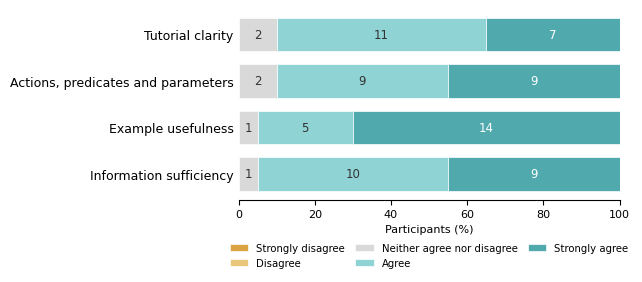

In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# ============================================================
# Paths
# ============================================================

OUTPUT_DIR = Path("liras_analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# Likert configuration
# ============================================================

LIKERT_ORDER = [
    "Strongly disagree",
    "Disagree",
    "Neither agree nor disagree",
    "Agree",
    "Strongly agree",
]

LIKERT_COLORS = {
    "Strongly disagree": "#D9A441",
    "Disagree": "#E8C77A",
    "Neither agree nor disagree": "#D9D9D9",
    "Agree": "#8FD3D5",
    "Strongly agree": "#4FA9AD",
}

# ============================================================
# Original DataFrame column names
# ============================================================

LIRAS_FEEDBACK = [
    "LIrAs: Syntax",
    "LIrAs: Scenario -> specification",
    "LIrAs: Synchronization",
    "LIrAs: Continuations",
    "LIrAs: Conditional constructs",
    "LIrAs: Skip/restart",
    "LIrAs: Confidence",
]

TUTORIAL_FEEDBACK = [
    "Tutorial: Clarity",
    "Tutorial: Actions/predicates/parameters",
    "Tutorial: Examples",
    "Tutorial: Sufficient information",
]

# ============================================================
# Display labels (independent from DataFrame columns)
# ============================================================

DISPLAY_LABELS = {
    "LIrAs: Syntax": "Syntax clarity",
    "LIrAs: Scenario -> specification":
        "Scenario-to-specification ease",
    "LIrAs: Synchronization": "Synchronization clarity",
    "LIrAs: Continuations": "Continuation clarity",
    "LIrAs: Conditional constructs":
        "Conditional construct clarity",
    "LIrAs: Skip/restart": "Skip/restart predictability",
    "LIrAs: Confidence": "Specification confidence",

    "Tutorial: Clarity": "Tutorial clarity",
    "Tutorial: Actions/predicates/parameters":
        "Actions, predicates and parameters",
    "Tutorial: Examples": "Example usefulness",
    "Tutorial: Sufficient information":
        "Information sufficiency",
}

# ============================================================
# Cohort selector
# ============================================================

def select_cohort(df, cohort="All"):

    if cohort == "All":
        return df.copy()

    return df[df["Cohort"] == cohort].copy()


# ============================================================
# Pretty labels
# ============================================================

def pretty_label(column):

    return DISPLAY_LABELS.get(
        column,
        column.replace("LIrAs: ", "")
              .replace("Tutorial: ", "")
    )


# ============================================================
# Compute counts and percentages
# ============================================================

def compute_likert_data(df, columns, cohort="All"):

    d = select_cohort(df, cohort)

    count_rows = []
    pct_rows = []

    for col in columns:

        counts = (
            d[col]
            .value_counts()
            .reindex(LIKERT_ORDER, fill_value=0)
        )

        total = counts.sum()

        if total > 0:
            pct = counts / total * 100
        else:
            pct = counts.astype(float)

        label = pretty_label(col)

        count_rows.append([
            label,
            *counts.tolist()
        ])

        pct_rows.append([
            label,
            *pct.tolist()
        ])

    count_df = pd.DataFrame(
        count_rows,
        columns=["Item", *LIKERT_ORDER]
    ).set_index("Item")

    pct_df = pd.DataFrame(
        pct_rows,
        columns=["Item", *LIKERT_ORDER]
    ).set_index("Item")

    return count_df, pct_df


# ============================================================
# Plot function
# ============================================================

def plot_likert(
    df,
    columns,
    cohort="All",
    title=None,
    save_name=None,
):

    count_df, pct_df = compute_likert_data(
        df,
        columns,
        cohort=cohort
    )

    # --------------------------------------------------------
    # Diagnostic tables
    # --------------------------------------------------------

    print(f"\nLikert counts — cohort: {cohort}")
    display(count_df)

    print(f"\nLikert percentages — cohort: {cohort}")
    display(pct_df.round(1))

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    n_items = len(columns)

    fig_height = max(
        3.0,
        0.42 * n_items + 1.3
    )

    fig, ax = plt.subplots(
        figsize=(6.5, fig_height)
    )

    y = np.arange(n_items)
    left = np.zeros(n_items)

    # --------------------------------------------------------
    # Stacked bars
    # --------------------------------------------------------

    for category in LIKERT_ORDER:

        widths = pct_df[category].to_numpy()
        counts = count_df[category].to_numpy()

        ax.barh(
            y,
            widths,
            left=left,
            label=category,
            color=LIKERT_COLORS[category],
            edgecolor="white",
            linewidth=0.5,
            height=0.72,
        )

        # ----------------------------------------------------
        # Absolute counts inside each segment
        # ----------------------------------------------------

        for i, (width, count) in enumerate(
            zip(widths, counts)
        ):

            if count == 0:
                continue

            x_center = left[i] + width / 2

            # Dark text for light segments
            if category in [
                "Disagree",
                "Neither agree nor disagree",
                "Agree",
            ]:
                text_color = "#333333"
            else:
                text_color = "white"

            ax.text(
                x_center,
                i,
                f"{int(count)}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=text_color,
                fontweight="medium",
            )

        left += widths

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax.set_yticks(y)

    ax.set_yticklabels(
        pct_df.index,
        fontsize=9,
    )

    ax.set_xlim(0, 100)

    ax.set_xticks(
        [0, 20, 40, 60, 80, 100]
    )

    ax.tick_params(
        axis="x",
        labelsize=8,
    )

    ax.tick_params(
        axis="y",
        length=0,
    )

    ax.set_xlabel(
        "Participants (%)",
        fontsize=8,
    )

    ax.invert_yaxis()

    # --------------------------------------------------------
    # Clean frame
    # --------------------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    handles, labels = ax.get_legend_handles_labels()

    ordered_handles = [
        handles[labels.index(category)]
        for category in LIKERT_ORDER
    ]

    ax.legend(
        ordered_handles,
        LIKERT_ORDER,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
        fontsize=7.3,
        columnspacing=1.0,
        handlelength=1.8,
    )

    fig.tight_layout()

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    if save_name:

        save_path = OUTPUT_DIR / save_name

        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

        pdf_path = save_path.with_suffix(".pdf")

        fig.savefig(
            pdf_path,
            format="pdf",
            bbox_inches="tight",
        )

        print(f"Saved PNG: {save_path.resolve()}")
        print(f"Saved PDF: {pdf_path.resolve()}")

    plt.show()

    return count_df, pct_df


# ============================================================
# LIrAs perception
# ============================================================

liras_counts, liras_pct = plot_likert(
    analysis_df,
    LIRAS_FEEDBACK,
    cohort="All",
    title=None,
    save_name="feedback_liras_likert_paper.png",
)


# ============================================================
# Tutorial perception
# ============================================================

tutorial_counts, tutorial_pct = plot_likert(
    analysis_df,
    TUTORIAL_FEEDBACK,
    cohort="All",
    title=None,
    save_name="feedback_tutorial_likert_paper.png",
)
